In [9]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [10]:
words = open('names.txt', 'r').read().splitlines()
len(words)

32033

In [11]:
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [12]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocub_size = len(itos)
print(vocub_size)


27


In [13]:
# build the dataset 
block_size =3

def build_dataset(words):
    X, Y = [], []

    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(len(words)*0.8)
n2 = int(len(words)*0.9)

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [14]:
n_embd = 10
n_hidden = 200

g = torch.Generator().manual_seed(233)
C = torch.randn((vocub_size, n_embd), generator=g )
W1 = torch.randn((n_embd*block_size, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn((n_hidden, vocub_size), generator=g)
b2 = torch.randn((vocub_size), generator=g)

parameters = [C, W1, b1, W2, b2 ]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True


11897


In [15]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    #mini batch
    ix = torch.randint(0,Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    emb = C[Xb] # C is 27 * 10 and Xb is 3 charachers and 32 are the minibatch
    # one example of C[Xb] = 1 example  * 3 * 10
    embcat = emb.view(emb.shape[0], -1)
    h = torch.tanh(embcat @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update 
    lr = 0.1 if i < 1000000 else 0.01  # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track status 
    if i % 1000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())






      0/ 200000: 25.8410
   1000/ 200000: 4.0468
   2000/ 200000: 3.4997
   3000/ 200000: 2.8907
   4000/ 200000: 2.8690
   5000/ 200000: 3.0013
   6000/ 200000: 3.0306
   7000/ 200000: 2.4459
   8000/ 200000: 3.3258
   9000/ 200000: 2.3293
  10000/ 200000: 2.7120
  11000/ 200000: 2.3025
  12000/ 200000: 2.4793
  13000/ 200000: 2.4220
  14000/ 200000: 2.4969
  15000/ 200000: 2.6839
  16000/ 200000: 2.7348
  17000/ 200000: 2.8236
  18000/ 200000: 2.5308
  19000/ 200000: 2.4896
  20000/ 200000: 2.1652
  21000/ 200000: 2.1344
  22000/ 200000: 2.6705
  23000/ 200000: 2.5073
  24000/ 200000: 2.9881
  25000/ 200000: 2.2903
  26000/ 200000: 2.4783
  27000/ 200000: 2.4779
  28000/ 200000: 2.4572
  29000/ 200000: 1.7874
  30000/ 200000: 2.3608
  31000/ 200000: 2.4179
  32000/ 200000: 2.0311
  33000/ 200000: 2.7571
  34000/ 200000: 2.3855
  35000/ 200000: 2.6370
  36000/ 200000: 2.6243
  37000/ 200000: 2.7068
  38000/ 200000: 2.1532
  39000/ 200000: 1.9657
  40000/ 200000: 2.1994
  41000/ 200000

KeyboardInterrupt: 

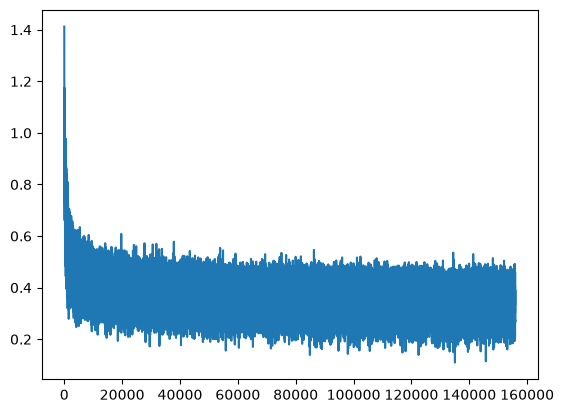

In [16]:
plt.plot(lossi)

In [17]:
# this is just to compare losses to check weather we are optimizing or not
@torch.no_grad()
def split_loss(split):
    x, y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test': (Xte, Yte)
    }[split]
    emb = C[x]
    embcat = emb.view(emb.shape[0], -1)
    h = torch.tanh(embcat @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, y)
    print(split, loss, loss.item())
    return

split_loss('train')
split_loss('val')

train tensor(2.2411) 2.2410902976989746
val tensor(2.3029) 2.30289363861084


In [18]:
# sample from the model 
g = torch.Generator().manual_seed(333)

for _ in range(10):
    # ix softmax 
    out = []
    context = [0]* block_size

    while True:
        emb = C[torch.tensor([context])] # 1, block_size, n_embd
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        print(emb.view(1, -1).shape)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)

        # sample from the distripution 
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        #shift the context window 
        context = context[1:] + [ix]
        out.append(ix)
 
        if ix == 0:
            break

    # we are making it character after we get the numbers 
    print(''.join(itos[i] for i in out))



torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
rayza.
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
alonamircceel.
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
darlessabyah.
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
alor.
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
nard.
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([1, 30])
torch.Size([

[0, 0, 0]